# Taller 11: Máquinas de Soporte Vectorial (SVM)


## 1. Librerías

In [ ]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_digits
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict, GridSearchCV
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

# Modelos de los talleres 9 (Naive Bayes) y 10 (red neuronal) para la comparación
from sklearn.naive_bayes import CategoricalNB, GaussianNB
from sklearn.neural_network import MLPClassifier

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

## 2. Carga y exploración del dataset
El dataset digits contiene 1797 imágenes de 8×8 píxeles de dígitos (0–9) escritos a mano. Cada píxel es un valor entero entre 0 y 16 (intensidad), por lo que cada imagen se representa como un vector de 64 características.

In [ ]:
digits = load_digits()
X, y = digits.data, digits.target

print("Forma de X:", X.shape)
print("Forma de y:", y.shape)
print("Clases:", np.unique(y))
print("Rango de valores de los píxeles:", X.min(), "-", X.max())

Forma de X: (1797, 64)
Forma de y: (1797,)
Clases: [0 1 2 3 4 5 6 7 8 9]
Rango de valores de los píxeles: 0.0 - 16.0


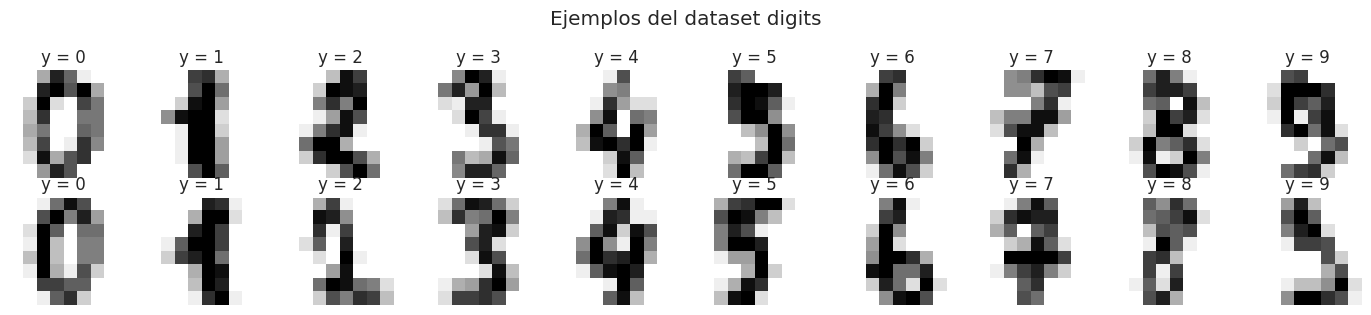

In [ ]:
# Algunas imágenes de ejemplo
fig, axes = plt.subplots(2, 10, figsize=(14, 3.2))
for ax, img, label in zip(axes.ravel(), digits.images, digits.target):
    ax.imshow(img, cmap="gray_r")
    ax.set_title(f"y = {label}")
    ax.axis("off")
plt.suptitle("Ejemplos del dataset digits")
plt.tight_layout()
plt.show()

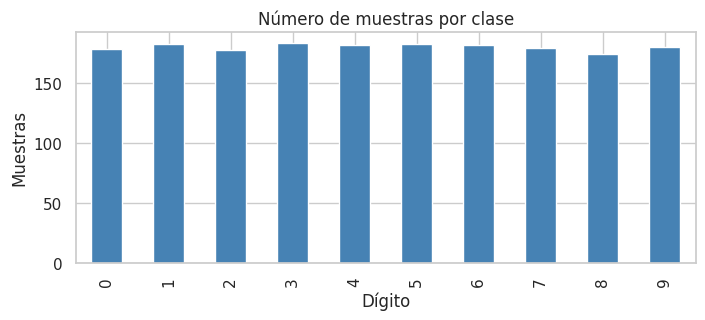

In [ ]:
# Distribución de clases
pd.Series(y).value_counts().sort_index().plot(kind="bar", figsize=(8, 3), color="steelblue")
plt.title("Número de muestras por clase")
plt.xlabel("Dígito"); plt.ylabel("Muestras")
plt.show()

Las clases están prácticamente balanceadas, así que la exactitud o accuracy es una métrica representativa; aun así reportamos también precisión, recall y F1 en promedio *macro*.

## 3. Metodología de evaluación

Para evaluar los modelos usamos validación cruzada estratificada con 10 folds. La idea es dividir los datos en 10 partes que mantienen la proporción de cada clase, y entrenar el modelo 10 veces: en cada vuelta entrena con 9 partes y prueba con la que quedó afuera. El resultado que reportamos es el promedio de las 10 iteraciones, junto con su desviación estándar, para tener una idea de qué tan estable es el modelo.
Como indicadores de desempeño calculamos:
1- Accuracy: qué fracción de los dígitos clasificó bien.

2- Precision (macro): entre todo lo que el modelo predijo como clase c, qué proporción era efectivamente c. Se promedia sobre las 10 clases.

3- Recall (macro): de todos los dígitos que sí eran clase c, cuántos logró encontrar el modelo.

4-F1 (macro): la media armónica entre precisión y recall, que resume ambas en un solo número.

Sobre el preprocesamiento: las SVM son sensibles a la escala de las variables (al fin y al cabo trabajan con distancias y productos punto), así que aplicamos StandardScaler antes de entrenar. Hay un detalle importante aquí: el escalado va dentro de un Pipeline, no antes de partir los datos. Así, en cada fold el scaler se ajusta únicamente con los datos de entrenamiento y luego se aplica al de prueba, evitando que información del conjunto de prueba se filtre al entrenamiento (lo que se conoce como data leakage).


In [ ]:
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)
SCORING = ["accuracy", "precision_macro", "recall_macro", "f1_macro"]

def evaluar(modelo, nombre):
    # Aplica k-fold al modelo y devuelve un diccionario con media y desviación de cada métrica.
    t0 = time.time()
    res = cross_validate(modelo, X, y, cv=cv, scoring=SCORING, n_jobs=-1)
    fila = {"Modelo": nombre}
    for m in SCORING:
        fila[m] = res[f"test_{m}"].mean()
        fila[m + "_std"] = res[f"test_{m}"].std()
    fila["tiempo_s"] = time.time() - t0
    fila["_acc_folds"] = res["test_accuracy"]
    return fila

def tabla(filas):
    df = pd.DataFrame(filas).set_index("Modelo")
    vista = pd.DataFrame(index=df.index)
    for m in SCORING:
        vista[m] = df[m].map("{:.4f}".format) + " ± " + df[m + "_std"].map("{:.4f}".format)
    vista["tiempo (s)"] = df["tiempo_s"].round(2)
    return vista

## 4. Comparación de kernels con hiperparámetros por defecto

SVC viene con cuatro kernels:

| Kernel | Qué hace |
|---|---|
| linear | $x^\top x'$ — busca un hiperplano que separe las clases. |
| poly | $(\gamma\, x^\top x' + r)^d$ — fronteras polinomiales de grado $d$. |
| rbf | $\exp(-\gamma \lVert x - x' \rVert^2)$ — gaussiana; permite fronteras muy flexibles. |
| sigmoid | $\tanh(\gamma\, x^\top x' + r)$ — equivale a una neurona con activación tanh. |

Todos los kernels se evalúan con sus valores por defecto (C=1, gamma='scale', degree=3).

Un detalle de SVC: para clasificación multiclase usa la estrategia **uno-contra-uno**. Como tenemos 10 dígitos, esto significa entrenar $\binom{10}{2} = 45$ clasificadores binarios distintos y resolver la clase final por votación entre todos ellos.

In [ ]:
kernels = ["linear", "poly", "rbf", "sigmoid"]
filas_default = []
for k in kernels:
    modelo = make_pipeline(StandardScaler(), SVC(kernel=k, random_state=RANDOM_STATE))
    filas_default.append(evaluar(modelo, f"SVM {k} (default)"))

tabla(filas_default)

,accuracy,precision_macro,recall_macro,f1_macro,tiempo (s)
Modelo,,,,,
SVM linear (default),0.9805 ± 0.0051,0.9817 ± 0.0047,0.9805 ± 0.0051,0.9805 ± 0.0051,3.32
SVM poly (default),0.9621 ± 0.0150,0.9697 ± 0.0100,0.9623 ± 0.0149,0.9633 ± 0.0138,1.50
SVM rbf (default),0.9844 ± 0.0093,0.9853 ± 0.0091,0.9843 ± 0.0094,0.9843 ± 0.0094,1.81
SVM sigmoid (default),0.9449 ± 0.0140,0.9482 ± 0.0132,0.9449 ± 0.0137,0.9450 ± 0.0138,0.90


## 5. Ajuste de hiperparámetros por kernel

Comparar kernels solo con los valores por defecto puede ser injusto: quizá un kernel rinde peor no porque sea peor, sino porque no se le dieron sus hiperparámetros adecuados. Por eso, para cada kernel buscamos la mejor combinación de hiperparámetros con GridSearchCV, y luego comparamos kernels ya optimizados.

Aquí hay un problema metodológico: si elegimos los hiperparámetros mirando los mismos datos con los que después reportamos el despeño, el resultado queda sesgado a favor del modelo. La solución es la validación cruzada anidada, que separa la búsqueda de hiperparámetros de la evaluación:

\- Bucle interno (5 folds): GridSearchCV prueba las combinaciones de hiperparámetros usando únicamente el conjunto de entrenamiento del fold externo.

 \- Bucle externo (10 folds): evalúa el modelo (con los hiperparámetros ya elegidos) sobre datos que nunca participaron en esa elección.

Los hiperparámetros que exploramos para cada kernel son:

\- C: controla la penalización por errores. Un C grande fuerza al modelo a cometer menos errores en entrenamiento, a costa de un margen más estrecho.

\- gamma: determina el alcance de la influencia de cada muestra (aplica a rbf, poly y sigmoid).

\- degree: el grado del polinomio (solo poly).

\- coef0: el término independiente r (kernels poly y sigmoid).

In [ ]:
param_grids = {
    "linear":  {"svc__C": [0.001, 0.01, 0.1, 1, 10]},
    "poly":    {"svc__C": [0.1, 1, 10, 100], "svc__degree": [2, 3, 4],
                "svc__gamma": ["scale", 0.01], "svc__coef0": [0, 1]},
    "rbf":     {"svc__C": [0.1, 1, 10, 100], "svc__gamma": ["scale", 0.001, 0.005, 0.01, 0.05]},
    "sigmoid": {"svc__C": [0.1, 1, 10, 100], "svc__gamma": ["scale", 0.0001, 0.001, 0.01],
                "svc__coef0": [0, 1]},
}

inner_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
filas_tuned = []
for k in kernels:
    pipe = make_pipeline(StandardScaler(), SVC(kernel=k, random_state=RANDOM_STATE))
    grid = GridSearchCV(pipe, param_grids[k], cv=inner_cv, scoring="accuracy", n_jobs=-1)
    filas_tuned.append(evaluar(grid, f"SVM {k} (ajustado)"))
    # Mejores hiperparámetros sobre todo el dataset (solo como referencia)
    grid.fit(X, y)
    print(f"{k:8s} -> mejores parámetros: {grid.best_params_}")

tabla(filas_tuned)

linear   -> mejores parámetros: {'svc__C': 0.1}


In [ ]:
# Comparación visual: accuracy en cada uno de los 10 folds
datos_box = pd.DataFrame({f["Modelo"]: f["_acc_folds"] for f in filas_default + filas_tuned})
plt.figure(figsize=(12, 4.5))
sns.boxplot(data=datos_box, orient="h", palette="Set2")
plt.xlabel("Accuracy en cada fold (10-fold CV)")
plt.title("Desempeño de los kernels de la SVM")
plt.tight_layout()
plt.show()

In [ ]:
# Mejor kernel según el accuracy promedio de la validación cruzada anidada
resumen = pd.DataFrame(filas_tuned).set_index("Modelo")
mejor_nombre = resumen["accuracy"].idxmax()
mejor_kernel = mejor_nombre.split()[1]
print("Mejor configuración:", mejor_nombre)
print(f"Accuracy promedio: {resumen.loc[mejor_nombre, 'accuracy']:.4f} ± {resumen.loc[mejor_nombre, 'accuracy_std']:.4f}")

## 6. Análisis del mejor modelo

Con el mejor kernel, obtenemos con cross_val_predict la predicción de cada muestra cuando estuvo en el fold de prueba (10-fold). Así la matriz de confusión y el reporte por clase reflejan desempeño en datos no vistos.

In [ ]:
mejor_grid = GridSearchCV(make_pipeline(StandardScaler(), SVC(kernel=mejor_kernel, random_state=RANDOM_STATE)),
                          param_grids[mejor_kernel], cv=inner_cv, scoring="accuracy", n_jobs=-1)
y_pred = cross_val_predict(mejor_grid, X, y, cv=cv, n_jobs=-1)

print(classification_report(y, y_pred, digits=4))

fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(confusion_matrix(y, y_pred), display_labels=digits.target_names).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title(f"Matriz de confusión – SVM {mejor_kernel} (10-fold CV)")
plt.show()

In [ ]:
# Dígitos mal clasificados
errores = np.where(y != y_pred)[0]
print(f"Total de errores: {len(errores)} de {len(y)} muestras")

n = min(len(errores), 20)
if n:
    cols = 10
    filas = int(np.ceil(n / cols))
    fig, axes = plt.subplots(filas, cols, figsize=(14, 1.7 * filas), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    for ax, i in zip(axes.ravel(), errores[:n]):
        ax.imshow(digits.images[i], cmap="gray_r")
        ax.set_title(f"real {y[i]} / pred {y_pred[i]}", fontsize=9, color="crimson")
    plt.suptitle("Ejemplos de dígitos mal clasificados")
    plt.tight_layout()
    plt.show()

In [ ]:
# Número de vectores de soporte del modelo final (entrenado con todos los datos)
mejor_grid.fit(X, y)
svc_final = mejor_grid.best_estimator_.named_steps["svc"]
print("Hiperparámetros finales:", mejor_grid.best_params_)
print("Vectores de soporte totales:", svc_final.n_support_.sum(), f"({svc_final.n_support_.sum() / len(X):.1%} de las muestras)")
print("Vectores de soporte por clase:", {int(d): int(n) for d, n in zip(digits.target_names, svc_final.n_support_)})

## 7. Comparación con los talleres 9 y 10

Comparar con los resultados que reportamos en los talleres 9 y 10 tal cual no funcionaría: allí usamos particiones distintas (4-fold más 20 % de prueba en el Taller 9; división 60/20/20 en el Taller 10), así que sus números no son directamente comparables con los de este cuaderno. Para nivelar la cancha, re-entrenamos esos modelos desde cero siguiendo el mismo protocolo de este taller: mismo dataset, mismo StratifiedKFold de 10 folds con la misma semilla y las mismas métricas.

En cuanto a configuración, cada modelo conserva los hiperparámetros que se eligieron en su taller original:

| Taller | Modelo | Configuración |
|---|---|---|
| 9 | Naive Bayes (CategoricalNB) | α = 0.5, min_categories=17. **Sin escalar**, porque requiere entradas enteras no negativas (0–16). Incluimos también GaussianNB` como referencia. |
| 10 | Red neuronal (MLPClassifier) | 1 capa oculta de 64 neuronas, activación logistic (elegida en el taller por su mayor balanced accuracy promedio en 5 semillas), solver='lbfgs', alpha=1e-4, tol=1e-6, max_iter=2000, max_fun=50000, con StandardScaler. |



In [ ]:
modelos_previos = [
    # Taller 9: Naive Bayes categórico (SIN escalar: requiere enteros >= 0)
    ("T9 – CategoricalNB (α=0.5)", CategoricalNB(alpha=0.5, min_categories=17)),
    ("T9 – GaussianNB",            GaussianNB()),
    # Taller 10: MLP de 64 neuronas ocultas, activación logistic (la elegida allá)
    ("T10 – MLP logistic (64)",
     make_pipeline(StandardScaler(),
                   MLPClassifier(hidden_layer_sizes=(64,), activation="logistic",
                                 solver="lbfgs", alpha=1e-4, tol=1e-6,
                                 max_iter=2000, max_fun=50000,
                                 random_state=RANDOM_STATE))),
]

filas_previos = [evaluar(m, nombre) for nombre, m in modelos_previos]
mejor_svm = [f for f in filas_tuned if f["Modelo"] == mejor_nombre][0]

comparacion = tabla(filas_previos + [mejor_svm])
comparacion.sort_values("accuracy", ascending=False)

In [ ]:
# (Opcional) Resultados reportados en los talleres 9 y 10 (sobre el 20 % de prueba reservado en cada taller).
# Rellenar con los valores reales; si se deja vacío, la celda no hace nada.
resultados_talleres_previos = {
    # "Taller 9 – CategoricalNB":  {"accuracy": 0.00, "f1_macro": 0.00},
    # "Taller 10 – MLP logistic": {"accuracy": 0.00, "f1_macro": 0.00},
}
if resultados_talleres_previos:
    display(pd.DataFrame(resultados_talleres_previos).T)

In [ ]:
# Gráfica comparativa
df_comp = pd.DataFrame(filas_previos + [mejor_svm]).set_index("Modelo").sort_values("accuracy")
colores = ["crimson" if n == mejor_nombre else "steelblue" for n in df_comp.index]
plt.figure(figsize=(9, 4.5))
plt.barh(df_comp.index, df_comp["accuracy"], xerr=df_comp["accuracy_std"], color=colores, capsize=4)
plt.xlim(0.75, 1.0)
plt.xlabel("Accuracy promedio (10-fold CV)")
plt.title("SVM vs. clasificadores de talleres anteriores")
for i, v in enumerate(df_comp["accuracy"]):
    plt.text(v + 0.003, i, f"{v:.4f}", va="center")
plt.tight_layout()
plt.show()

**Lectura de la comparación.** La SVM ajustada obtiene el mayor accuracy y F1 macro, seguida de la red neuronal del Taller 10 y, a bastante distancia, de los clasificadores bayesianos del Taller 9. Que Naive Bayes quede rezagado es coherente con su supuesto de independencia entre características: en imágenes los píxeles vecinos están fuertemente correlacionados. SVM y MLP, en cambio, sí capturan esas interacciones (la SVM mediante el kernel; la red mediante sus capas ocultas).

## 8. Conclusiones

1- Mejor kernel: polinomial (ajustado). Con validación cruzada anidada (10 folds externos, 5 internos) la SVM con kernel poly (grado 3, C=1, gamma=0.01, coef0=1) obtuvo accuracy ≈ 0.9905 ± 0.0066 y F1-macro ≈ 0.9905, el mejor resultado de todas las configuraciones. Solo se equivocó en 17 de las 1797 imágenes.

2- Ajustar hiperparámetros importa más que el kernel "de moda". Con valores por defecto el mejor fue rbf (≈ 0.984) y poly quedó en ≈ 0.962; tras ajustar, poly pasó a ser el mejor. El kernel sigmoid mejoró mucho (≈ 0.945 → ≈ 0.981) al reducir gamma. rbf ajustado (≈ 0.983) quedó prácticamente igual que con valores por defecto: gamma='scale' ya era una buena elección para este dataset, y las diferencias entre linear, rbf y sigmoid ajustados (todas ≈ 0.981–0.983) están dentro de una desviación estándar.

3- El problema es casi linealmente separable. El kernel lineal ya logra ≈ 0.981: en 64 dimensiones los dígitos se separan bien con hiperplanos, y un kernel polinomial de grado 3 (que captura interacciones entre píxeles) aporta el último punto porcentual.

4- Errores. Las clases más difíciles son el **9** (recall ≈ 0.967), el 8 y el 5, que se confunden por su forma parecida en baja resolución (8×8). El 0 se clasifica perfectamente.

5- Comparación con talleres anteriores. Bajo el mismo protocolo de 10-fold, la SVM con kernel polinomial (≈ 0.990) supera a los modelos de los talleres 9 y 10: el MLP del Taller 10 con activación logistic (≈ 0.974), el CategoricalNB del Taller 9 (≈ 0.907) y el GaussianNB (≈ 0.843). La ventaja sobre el MLP es de unos 1.7 puntos porcentuales y sobre Naive Bayes de más de 8. Esto es coherente con la teoría: Naive Bayes asume independencia entre píxeles, algo falso en imágenes, mientras que SVM y MLP modelan esas interacciones. La SVM además es más estable entre folds que Naive Bayes.

6- Costo. La SVM ajustada es la más costosa de entrenar por la búsqueda de hiperparámetros (cada combinación se entrena 5 × 10 veces), pero el modelo final es compacto: usa ~35 % de las muestras como vectores de soporte.
